# Example 9.1 — Droplet Trajectory Analysis

**Chapter 9: Step-by-Step Trajectory Synthesis**

This notebook generates the desired drop-shaped trajectory, implements the kinematic analysis of the four-bar mechanism using the Weierstrass solution, and evaluates the error for an initial design.

## 1. Import dependencies

In [1]:
import matplotlib.pyplot as plt
from numpy import *


## 2. Desired trajectory: drop-shaped curve

In [6]:
def trayectoria_gota(n=20):
    """Generates n points on the drop-shaped trajectory."""
    t = linspace(0, 2 * pi, n, endpoint=False)
    factor = 1 - 0.5 * sin(t / 2)
    xd = 100 + 50 * cos(t) * factor
    yd = 100 + 50 * sin(t) * factor
    return xd, yd

n_pts = 20
xd, yd = trayectoria_gota(n_pts)

print('Desired trajectory (first 5 points):')
print(f"{'i':>3}  {'xd':>8}  {'yd':>8}")
for i in range(5):
    print(f"{i:>3}  {xd[i]:>8.2f}  {yd[i]:>8.2f}")

Desired trajectory (first 5 points):
  i        xd        yd
  0    150.00    100.00
  1    143.83    114.24
  2    134.20    124.85
  3    122.72    131.27
  4    110.91    133.58


## 3. Kinematic analysis — Weierstrass solution

In [7]:
def analizar_mecanismo(r1, r2, r3, r4, theta2):
    """Calculates θ3 and θ4 for the given position of θ2."""
    A = 2 * r4 * (r1 - r2 * cos(theta2))
    B = -2 * r2 * r4 * sin(theta2)
    C = r1**2 + r2**2 + r4**2 - r3**2 - 2 * r1 * r2 * cos(theta2)

    d = A**2 + B**2 - C**2
    if d < 0:
        return None, None

    t4 = 2 * arctan2(-B + sqrt(d), A - C)
    t3 = arctan2(
        (r4 * sin(t4) - r2 * sin(theta2)) / r3,
        (r1 + r4 * cos(t4) - r2 * cos(theta2)) / r3
    )
    return t3, t4

## 4. Error evaluation for an initial design

In [8]:
r1, r2, r3, r4 = 80.0, 40.0, 100.0, 90.0
t2_vals = linspace(0, 2 * pi, n_pts, endpoint=False)
errores = []

for i in range(n_pts):
    t3, t4 = analizar_mecanismo(r1, r2, r3, r4, t2_vals[i])
    if t3 is not None:
        xa = r2 * cos(t2_vals[i]) + 30 * cos(t3) - 10 * sin(t3)
        ya = r2 * sin(t2_vals[i]) + 30 * sin(t3) + 10 * cos(t3)
        errores.append(sqrt((xa - xd[i])**2 + (ya - yd[i])**2))

print(f'r1={r1}, r2={r2}, r3={r3}, r4={r4} mm')
print(f'Mean trajectory error: {mean(errores):.4f} mm')
print(f'Maximum error:       {max(errores):.4f} mm')

r1=80.0, r2=40.0, r3=100.0, r4=90.0 mm
Mean trajectory error: 121.0127 mm
Maximum error:       132.5328 mm


## 5. Visualization

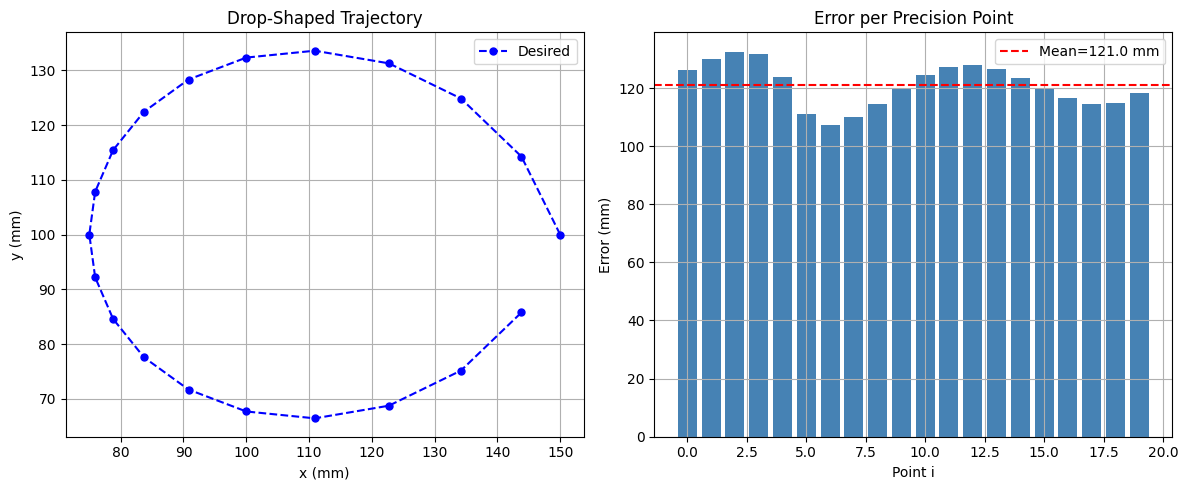

Figure saved as droplet_trajectory_analysis.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(xd, yd, 'b--o', ms=5, label='Desired')
axes[0].set_title('Drop-Shaped Trajectory')
axes[0].set_xlabel('x (mm)')
axes[0].set_ylabel('y (mm)')
axes[0].legend()
axes[0].grid(True)

axes[1].bar(range(len(errores)), errores, color='steelblue')
axes[1].axhline(mean(errores), color='r', ls='--', label=f'Mean={mean(errores):.1f} mm')
axes[1].set_title('Error per Precision Point')
axes[1].set_xlabel('Point i')
axes[1].set_ylabel('Error (mm)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('droplet_trajectory_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print('Figure saved as droplet_trajectory_analysis.png')